In [108]:
import pandas as pd
df = pd.read_csv("../data/jengo_sales_raw.csv")
df.shape

(3414, 13)

In [109]:
df.head(5)

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
0,ORD-12323,05/08/2026,C0916,Eldoret,Jepkemoi,Rice 5kg,Groceries,2.0,790.0,0.0,M-Pesa,Completed,David Kiprop
1,ORD-12919,2026-10-02,C0211,Mombasa,Hamisi,Cooking Oil 3L,Groceries,10.0,720.0,0.0,M-Pesa,completed,David Kiprop
2,ORD-11018,11/04/2026,C0009,Nairobi,Kamau,Maize Flour 2kg,Groceries,1.0,150.0,0.0,M-Pesa,Completed,David Kiprop
3,ORD-12094,2026-07-14,C1021,Nairobi,Wanjiku,Rice 5kg,Groceries,2.0,KES 790,0.0,Mpesa,Completed,Kevin Kiplagat
4,ORD-12295,02/08/2026,C0264,Mombasa,Hamisi,Sugar 2kg,Groceries,6.0,330.0,0.1,M-Pesa,completed,James Mwangi


In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3414 entries, 0 to 3413
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        3414 non-null   str    
 1   order_date      3414 non-null   str    
 2   customer_id     3306 non-null   str    
 3   branch          3414 non-null   str    
 4   sales_rep       3244 non-null   str    
 5   product         3414 non-null   str    
 6   category        3414 non-null   str    
 7   quantity        3347 non-null   float64
 8   unit_price_kes  3414 non-null   str    
 9   discount_pct    3190 non-null   str    
 10  payment_method  3313 non-null   str    
 11  order_status    3414 non-null   str    
 12  customer_name   3279 non-null   str    
dtypes: float64(1), str(12)
memory usage: 346.9 KB


In [111]:
df.describe()

,quantity
count,3347.000000
mean,4.576636
std,48.717629
min,-1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,999.000000


In [112]:
df.isna().sum()

order_id            0
order_date          0
customer_id       108
branch              0
sales_rep         170
product             0
category            0
quantity           67
unit_price_kes      0
discount_pct      224
payment_method    101
order_status        0
customer_name     135
dtype: int64

Here is a summary of the what the output shows

The dataset has 3,414 rows and 13 columns. The first five rows show orders from Eldoret, Mombasa and Nairobi, all for groceries and all paid by M-Pesa. Prices appear in two styles (`790.0` and `KES 790`), and status is written as both `Completed` and `completed`.`quantity` is the only numeric column; the other 12 are text. Seven columns are complete, and six have missing values. Only `quantity` is summarized. The average is about 4.6, the median is 1, the minimum is -1 and the maximum is 999.
Missing values by column:
   - `discount_pct`: 224
   - `sales_rep`: 170
   - `customer_name`: 135
   - `customer_id`: 108
   - `payment_method`: 101
   - `quantity`: 67

In [113]:
df["branch"].value_counts()

branch
Nairobi     1129
Mombasa      609
Nakuru       428
Kisumu       318
Eldoret      292
nairobi       94
Nbi           91
NAIROBI       89
Msa           54
Mombasa       49
nakuru        46
Nakuru        44
kisumu        41
mombasa       36
KISUMU        33
Eldoret.      31
eldoret       30
Name: count, dtype: int64

In [114]:
df["payment_method"].value_counts(dropna=False)

payment_method
M-Pesa           1485
Cash              576
Card              186
m-pesa            164
MPESA             160
M-pesa            155
Mpesa             153
cash              128
CASH              122
NaN               101
Bank Transfer      79
card               39
Visa               34
bank transfer      20
Bank               12
Name: count, dtype: int64

In [115]:
df["order_status"].value_counts()

order_status
Completed    1554
completed     779
COMPLETE      733
Returned      126
Cancelled     122
Pending        70
RETURNED        7
cancelled       6
CANCELLED       5
PENDING         5
returned        4
pending         3
Name: count, dtype: int64

In [116]:
df["order_status"].value_counts()

order_status
Completed    1554
completed     779
COMPLETE      733
Returned      126
Cancelled     122
Pending        70
RETURNED        7
cancelled       6
CANCELLED       5
PENDING         5
returned        4
pending         3
Name: count, dtype: int64

In [117]:
df["category"].value_counts()

category
Groceries       1365
Household        710
Electronics      539
Apparel          274
Groceries         97
GROCERIES         85
groceries         77
Electronics       44
HOUSEHOLD         41
household         41
Household         33
electronics       29
ELECTRONICS       25
APPAREL           22
Apparel           18
apparel           14
Name: count, dtype: int64

In [118]:
df.duplicated().sum()

np.int64(131)

In [119]:
df[df["quantity"].isin([0, 999, -1])]

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
329,ORD-13060,2026-10-13,C0130,Eldoret,Jepkemoi,Sugar 2kg,Groceries,999.0,330.0,0.0,M-Pesa,Completed,John Otieno
479,ORD-12920,2026-10-02,C0685,Mombasa,Zainab,Power Bank 10000mAh,Electronics,-1.0,2600.0,0.15,M-Pesa,Completed,Mary Achieng
603,ORD-10675,07/03/2026,C0451,Mombasa,Hamisi,Detergent 1kg,Household,999.0,320.0,0.0,M-Pesa,Cancelled,Mary Achieng
838,ORD-11844,"Jun 23, 2026",C0996,Nairobi,Kamau,Phone Charger,Electronics,999.0,KES 800,0.0,M-pesa,COMPLETE,Amina Hassan
849,ORD-12442,2026-08-18,C0150,Mombasa,Hamisi,Maize Flour 2kg,Groceries,-1.0,150.0,0,MPESA,COMPLETE,Grace Njeri
863,ORD-10006,01/01/2026,C0882,Nairobi,Wanjiku,Bread Loaf,Groceries,-1.0,60.0,NaN,M-Pesa,completed,Faith Mutheu
987,ORD-12811,"Sep 21, 2026",C0087,Nairobi,Kamau,Milk 500ml,Groceries,999.0,65.0,0.0,m-pesa,completed,James Mwangi
1028,ORD-10226,25/01/2026,C1278,Mombasa,Hamisi,Cooking Oil 3L,Groceries,-1.0,720.0,0.0,M-Pesa,completed,James Mwangi
1115,ORD-11501,"May 24, 2026",C0880,Nairobi,Kamau,Bread Loaf,Groceries,0.0,60.0,0.0,m-pesa,Cancelled,Samuel Chebet
1134,ORD-11659,05/06/2026,C0454,Kisumu,NaN,Bread Loaf,Groceries,0.0,60.0,0.0,Cash,Completed,faith mutheu


In [120]:
df["unit_price_kes"].astype(str).str.contains("KES").sum()

np.int64(340)

In [121]:
df["discount_pct"].value_counts(dropna=False).head(15)

discount_pct
0.0     2086
0        238
0%       232
NaN      224
0.1      145
0.05     120
0.15      69
0.2       58
0.25      41
0.3       40
10        27
10%       26
5%        22
5         22
20        11
Name: count, dtype: int64

In [122]:
df["order_date"].sample(15, random_state=1)

1881      2026-08-08
1195      2026-04-30
3106      21/04/2026
2611        05-01-26
2427        01-01-26
1141      2026-05-10
2719      2026-10-01
453       2026-05-29
1381      27/08/2026
1357      2026-03-08
3108      15/03/2026
254         26-04-26
2087      2026-01-07
1403        26-01-26
2856    Jan 31, 2026
Name: order_date, dtype: str

Output after further investigating the dataset

6. **`branch` counts**: There are 5 branches, listed under 17 spellings (such as `nairobi`, `NAIROBI`, `Nbi`, `Msa`, `Eldoret.`). `Mombasa` and `Nakuru` each appear twice as separate entries. Nairobi has the most orders.

7. **`payment_method` counts**: There are 15 labels, including several spellings of M-Pesa, Cash, Card and Bank Transfer, plus `Visa`, `Bank` and 101 blanks. M-Pesa is the most common.

8. **`order_status` counts**: There are 12 labels in different capitalizations. Most orders are completed (`Completed`, `completed`, `COMPLETE`), and smaller numbers are Returned, Cancelled or Pending.

9. **`order_status` counts (second run)**: Same output as the cell above.

10. **`category` counts**: There are 4 categories (Groceries, Household, Electronics, Apparel), written in 16 ways. Groceries is the largest.

11. **`df.duplicated().sum()`**: 131 rows are exact duplicates of other rows.

12. **Quantity of 0, 999 or -1**: 25 rows have one of these quantities, across several branches, products and statuses. Order `ORD-10226` appears twice in this list.

13. **Prices containing "KES"**: 340 values in `unit_price_kes` include the text "KES".

14. **`discount_pct` counts**: The column mixes formats such as `0.0`, `0`, `0%`, `0.1`, `10` and `10%`. Most rows have a discount of 0, and 224 are blank.

15. **Sample of `order_date`**: The 15 sampled dates use several formats: `2026-08-08`, `21/04/2026`, `05-01-26` and `Jan 31, 2026`.

In [123]:
df["order_id"].duplicated().sum()

np.int64(160)

In [124]:
df_clean = df.copy()

df_clean["branch"] = (
    df_clean["branch"].str.strip().str.rstrip(".").str.lower()
    .map({"nairobi": "Nairobi", "nbi": "Nairobi",
          "mombasa": "Mombasa", "msa": "Mombasa",
          "kisumu": "Kisumu", "nakuru": "Nakuru", "eldoret": "Eldoret"})
)

df_clean["payment_method"] = (
    df_clean["payment_method"].str.strip().str.lower()
    .map({"m-pesa": "M-Pesa", "mpesa": "M-pesa",
         "cash": "Cash",
          "card": "Card", "visa": "Card",
          "bank transfer": "Bank Transfer", "bank": "Bank Transfer"})
          .fillna("Unknown")
)

df_clean["order_status"] = (
    df_clean["order_status"].str.strip().str.lower()
    .map({"completed": "Completed", "complete": "Completed",
          "cancelled": "Cancelled", "returned": "Returned",
          "pending": "Pending"})
)

df_clean["category"] = df_clean["category"].str.title()
df_clean["customer_name"] = df_clean["customer_name"].str.strip().str.title()

In [125]:
for col in ["branch", "payment_method", "order_status", "category"]:
    print(df_clean[col].value_counts(dropna=False), "\n")


branch
Nairobi    1403
Mombasa     748
Nakuru      518
Kisumu      392
Eldoret     353
Name: count, dtype: int64 

payment_method
M-Pesa           1804
Cash              826
M-pesa            313
Card              259
Bank Transfer     111
Unknown           101
Name: count, dtype: int64 

order_status
Completed    3066
Returned      137
Cancelled     133
Pending        78
Name: count, dtype: int64 

category
Groceries       1527
Household        792
Electronics      593
Apparel          310
Groceries         97
Electronics       44
Household         33
Apparel           18
Name: count, dtype: int64 



In [126]:
df.loc[df_clean["payment_method"] == "M-pesa", "payment_method"].value_counts()

payment_method
MPESA    160
Mpesa    153
Name: count, dtype: int64

In [127]:
df_clean = df.copy()

In [128]:
df_clean["payment_method"].value_counts(dropna=False)

payment_method
M-Pesa           1485
Cash              576
Card              186
m-pesa            164
MPESA             160
M-pesa            155
Mpesa             153
cash              128
CASH              122
NaN               101
Bank Transfer      79
card               39
Visa               34
bank transfer      20
Bank               12
Name: count, dtype: int64

In [129]:
df["branch"].value_counts()

branch
Nairobi     1129
Mombasa      609
Nakuru       428
Kisumu       318
Eldoret      292
nairobi       94
Nbi           91
NAIROBI       89
Msa           54
Mombasa       49
nakuru        46
Nakuru        44
kisumu        41
mombasa       36
KISUMU        33
Eldoret.      31
eldoret       30
Name: count, dtype: int64

In [130]:
df_clean["payment_method"] = (
    df_clean["payment_method"].str.strip().str.lower()
    .map({"m-pesa": "M-Pesa", "mpesa": "M-Pesa",
         "cash": "Cash",
          "card": "Card", "visa": "Card",
          "bank transfer": "Bank Transfer", "bank": "Bank Transfer"})
          .fillna("Unknown")
)

In [131]:
df_clean["payment_method"].value_counts(dropna=False)

payment_method
M-Pesa           2117
Cash              826
Card              259
Bank Transfer     111
Unknown           101
Name: count, dtype: int64

In [132]:
df_clean["unit_price_kes"] = pd.to_numeric(
    df_clean["unit_price_kes"].astype(str)
    .str.replace("KES", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

In [133]:
disc = pd.to_numeric(
    df_clean["discount_pct"].astype(str).str.replace("%","", regex=False).str.strip(),
    errors="coerce"
)
disc = disc.where(disc <= 1, disc /100)
df_clean["discount_pct"] = disc.fillna(0)

In [134]:
s = df_clean["order_date"].str.strip()
d = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
for fmt in ["%d/%m/%Y", "%b %d, %Y", "%d-%m-%y"]:
    d =d.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
df_clean["order_date"] = d    
    

In [135]:
df_clean["order_date"].isna().sum()

np.int64(0)

In [136]:
df_clean["order_date"].agg(["min", "max"])

min   2026-01-01
max   2027-03-15
Name: order_date, dtype: datetime64[us]

In [137]:
df_clean[df_clean["order_date"] > "2026-10-31"]

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
97,ORD-11678,2027-03-15,C0234,Mombasa,Hamisi,Sugar 2kg,Groceries,3.0,330.0,0.0,Cash,COMPLETE,Lucy Wanjiru
208,ORD-10461,2027-03-15,C0384,Eldoret,Kiprop,Laundry Soap Bar,Household,1.0,90.0,0.0,M-Pesa,COMPLETE,mary achieng
1227,ORD-12517,2027-03-15,C1084,Mombasa,Zainab,Sugar 2kg,Groceries,1.0,330.0,0.1,Bank Transfer,Completed,Nancy Wairimu
1502,ORD-10461,2027-03-15,C0384,Eldoret,Kiprop,Laundry Soap Bar,Household,1.0,90.0,0.0,M-Pesa,COMPLETE,mary achieng
2788,ORD-11344,2027-03-15,C1393,Nairobi,Otieno,Maize Flour 2kg,Groceries,1.0,150.0,0.0,Bank Transfer,COMPLETE,Samuel Chebet


In [138]:
bad = df_clean["order_date"] > "2026-10-31"
df.loc[bad, "order_date"]

97      2027-03-15
208     2027-03-15
1227    2027-03-15
1502    2027-03-15
2788    2027-03-15
Name: order_date, dtype: str

In [139]:
df_clean.loc[bad, "order_date"] = pd.NaT

In [140]:
df_clean["order_date"].agg(["min", "max"])
df_clean["order_date"].isna().sum()

np.int64(5)

In [141]:
df_clean["order_date"].agg(["min", "max"])

min   2026-01-01
max   2026-10-31
Name: order_date, dtype: datetime64[us]

In [142]:
df_clean["order_date"].isna().sum()

np.int64(5)

In [143]:
df_clean["order_date"].dtype

dtype('<M8[us]')

In [144]:
df_clean["unit_price_kes"].describe()

count      3414.000000
mean       1029.144698
std        4337.651634
min           0.000000
25%         150.000000
50%         330.000000
75%         800.000000
max      150000.000000
Name: unit_price_kes, dtype: float64

In [145]:
df_clean["discount_pct"].value_counts().sort_index()

discount_pct
0.00    2780
0.05     164
0.10     198
0.15      87
0.20      79
0.25      59
0.30      47
Name: count, dtype: int64

In [146]:
df_clean[df_clean["unit_price_kes"]== 0]

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
1171,ORD-11999,2026-07-06,C0602,Mombasa,Zainab,Maize Flour 2kg,Groceries,1.0,0.0,0.0,Card,COMPLETE,Nancy Wairimu
1676,ORD-10549,2026-02-25,C0519,Nairobi,Otieno,T-Shirt,Apparel,1.0,0.0,0.0,Cash,Cancelled,mary achieng
1733,ORD-12895,2026-09-30,C1257,Mombasa,Zainab,Laundry Soap Bar,Household,1.0,0.0,0.0,M-Pesa,Completed,Esther Atieno
1869,ORD-11049,2026-04-13,C0236,Kisumu,Odhiambo,Milk 500ml,Groceries,10.0,0.0,0.0,M-Pesa,Completed,Faith Mutheu
2607,ORD-11780,2026-06-18,C0772,NAIROBI,Wanjiku,T-Shirt,Apparel,1.0,0.0,0.0,M-Pesa,Completed,Esther Atieno
2930,ORD-13022,2026-10-11,C0388,Nairobi,Kamau,Cooking Oil 3L,Groceries,6.0,0.0,0.0,M-Pesa,completed,Brian Omondi


In [147]:
df_clean.sort_values("unit_price_kes", ascending=False).head(10)[["product", "unit_price_kes"]]

,product,unit_price_kes
356,School Shoes,150000.0
1587,Earphones,120000.0
2682,Rice 5kg,79000.0
32,Smart TV 32in,21500.0
342,Smart TV 32in,21500.0
2910,Smart TV 32in,21500.0
1482,Smart TV 32in,21500.0
1629,Smart TV 32in,21500.0
1549,Smart TV 32in,21500.0
2892,Smart TV 32in,21500.0



## How many zero prices
**6 rows have a price of 0** (cell [64]). There are two T-Shirts and one each of Maize Flour 2kg, Laundry Soap Bar, Milk 500ml and Cooking Oil 3L. One of the T-Shirt orders is Cancelled; the other five are Completed. Cell [61] matches this, with a minimum price of 0.

## Which products are in the top 10
In cell [65]:
- **Smart TV 32in** takes 7 of the 10 spots, all at 21,500.
- The top 3 are single rows:
  - **School Shoes**: 150,000
  - **Earphones**: 120,000
  - **Rice 5kg**: 79,000

**Rice 5kg** is the only one of these where your outputs also show its normal price. It's 790 in the earlier `head()` output, so 79,000 is exactly 100 times that. Your outputs don't show the usual price of School Shoes or Earphones, so I can't say from them how far off those two are. Cell [61] also shows the max (150,000) far above the 75th percentile (800).

## Discounts
After your cleaning, **only 7 distinct values remain, from 0 to 0.30** in steps of 0.05 (cell [62]):

| Discount | Rows |
|---|---|
| 0.00 | 2,780 |
| 0.05 | 164 |
| 0.10 | 198 |
| 0.15 | 87 |
| 0.20 | 79 |
| 0.25 | 59 |
| 0.30 | 47 |

That matches what you expected: only a handful of values between 0 and 0.30.

In [148]:
valid = df_clean["unit_price_kes"] > 0
med = df_clean[valid].groupby("product")["unit_price_kes"].median()
df_clean["median_price"] = df_clean["product"].map(med)

In [149]:
bad_price = (df_clean["unit_price_kes"] ==0) |(df_clean["unit_price_kes"] > 5 * df_clean["median_price"])

In [150]:
df_clean.loc[bad_price, ["order_id", "product", "unit_price_kes", "median_price"]]

,order_id,product,unit_price_kes,median_price
356,ORD-10230,School Shoes,150000.0,1500.0
1171,ORD-11999,Maize Flour 2kg,0.0,150.0
1587,ORD-12130,Earphones,120000.0,1200.0
1676,ORD-10549,T-Shirt,0.0,600.0
1733,ORD-12895,Laundry Soap Bar,0.0,90.0
1869,ORD-11049,Milk 500ml,0.0,65.0
2607,ORD-11780,T-Shirt,0.0,600.0
2682,ORD-13250,Rice 5kg,79000.0,790.0
2930,ORD-13022,Cooking Oil 3L,0.0,720.0


In [151]:
df_clean.loc[bad_price, "unit_price_kes"] = df_clean.loc[bad_price, "median_price"]
df_clean= df_clean.drop(columns="median_price")

In [152]:
df_clean["unit_price_kes"].describe()

count     3414.000000
mean       928.592560
std       2524.593408
min         60.000000
25%        150.000000
50%        330.000000
75%        800.000000
max      21500.000000
Name: unit_price_kes, dtype: float64

In [153]:
df_clean.groupby("product")["unit_price_kes"].agg(["min", "max"])

,min,max
product,,
Bluetooth Speaker,3800.0,3800.0
Bread Loaf,60.0,60.0
Charcoal 2kg,160.0,160.0
Cooking Oil 3L,720.0,720.0
Detergent 1kg,320.0,320.0
Earphones,1200.0,1200.0
Jeans,1800.0,1800.0
LED Bulb 9W,220.0,220.0
Laundry Soap Bar,90.0,90.0


I cannot know the true price, but a product's median price is a reasonable replacement. This is an assumption

In [154]:
df_clean["quantity"].describe()

count    3347.000000
mean        4.576636
std        48.717629
min        -1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max       999.000000
Name: quantity, dtype: float64

In [155]:
df_clean["quantity"].value_counts(dropna=False).sort_index()

quantity
-1.0        11
 0.0         6
 1.0      1697
 2.0       672
 3.0       388
 4.0       224
 5.0       146
 6.0       111
 10.0       84
 999.0       8
 NaN        67
Name: count, dtype: int64

In [156]:
df_clean[(df_clean["quantity"] <= 0) | (df_clean["quantity"] > 100)][["order_id", "product", "quantity", "order_status"]]

,order_id,product,quantity,order_status
329,ORD-13060,Sugar 2kg,999.0,Completed
479,ORD-12920,Power Bank 10000mAh,-1.0,Completed
603,ORD-10675,Detergent 1kg,999.0,Cancelled
838,ORD-11844,Phone Charger,999.0,COMPLETE
849,ORD-12442,Maize Flour 2kg,-1.0,COMPLETE
863,ORD-10006,Bread Loaf,-1.0,completed
987,ORD-12811,Milk 500ml,999.0,completed
1028,ORD-10226,Cooking Oil 3L,-1.0,completed
1115,ORD-11501,Bread Loaf,0.0,Cancelled
1134,ORD-11659,Bread Loaf,0.0,Completed


In [157]:
bad_qty = (df_clean["quantity"] <= 0) | (df_clean["quantity"] > 100)
df_clean.loc[bad_qty, "quantity"] = pd.NA

In [158]:
df_clean["quantity"].isna().sum()

np.int64(92)

In [159]:
df_clean["quantity"].describe()

count    3322.000000
mean        2.208609
std         1.844810
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        10.000000
Name: quantity, dtype: float64

Quantities < 0 or > 100 set to missing: rows excluded from revenue calculations."Duplicated come after that, and they're the trickiest step


In [160]:
df_clean.shape

(3414, 13)

In [161]:
df_clean.duplicated().sum()

np.int64(131)

In [162]:
df_clean["order_id"].duplicated().sum()

np.int64(160)

In [163]:
dups = df_clean[df_clean["order_id"].duplicated(keep=False)].sort_values("order_id")
dups.head(10)

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
502,ORD-10018,2026-01-01,C0880,Eldoret,Kiprop,Phone Charger,Electronics,1.0,800.0,0.0,Cash,Completed,AMINA HASSAN
1947,ORD-10018,2026-01-01,C0880,Eldoret,Kiprop,Phone Charger,Electronics,1.0,800.0,0.0,Cash,Completed,Amina Hassan
2225,ORD-10038,2026-01-03,C1281,Eldoret.,Jepkemoi,Detergent 1kg,Household,1.0,320.0,0.0,M-Pesa,Completed,Peter Kamau
1089,ORD-10038,2026-01-03,C1281,Eldoret.,Jepkemoi,Detergent 1kg,Household,1.0,320.0,0.0,M-Pesa,Completed,Peter Kamau
540,ORD-10051,2026-01-05,C0725,Nakuru,Mwangi,Detergent 1kg,Household,2.0,320.0,0.0,Cash,completed,Amina Hassan
2099,ORD-10051,2026-01-05,C0725,Nakuru,Mwangi,Detergent 1kg,Household,2.0,320.0,0.0,Cash,completed,Amina Hassan
2885,ORD-10084,2026-01-09,C0269,kisumu,Achieng,Maize Flour 2kg,Groceries,5.0,150.0,0.0,M-Pesa,COMPLETE,Amina Hassan
2238,ORD-10084,2026-01-09,C0269,kisumu,Achieng,Maize Flour 2kg,Groceries,5.0,150.0,0.0,M-Pesa,COMPLETE,Amina Hassan
918,ORD-10118,2026-01-14,C1062,Nairobi,Otieno,Jeans,Apparel,1.0,1800.0,0.0,M-Pesa,COMPLETE,Grace Njeri
2859,ORD-10118,2026-01-14,C1062,Nairobi,Otieno,Jeans,Apparel,1.0,1800.0,0.0,M-Pesa,COMPLETE,Grace Njeri


In [164]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [165]:
df_clean.shape
df_clean["order_id"].duplicated().sum()

np.int64(29)

In [166]:
df_clean.shape

(3283, 13)

In [167]:
dups = df_clean[df_clean["order_id"].duplicated(keep=False)].sort_values("order_id")

In [168]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [169]:
df_clean.shape

(3283, 13)

In [170]:
df_clean["order_id"].duplicated().sum()

np.int64(29)

In [171]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [172]:
df_clean.shape

(3283, 13)

In [173]:
df_clean["order_id"].duplicated().sum()

np.int64(29)

In [174]:
dups = df_clean[df_clean["order_id"].duplicated(keep=False)].sort_values("order_id")
dups.head(10)

,order_id,order_date,customer_id,branch,sales_rep,product,category,quantity,unit_price_kes,discount_pct,payment_method,order_status,customer_name
1903,ORD-10018,2026-01-01,C0880,Eldoret,Kiprop,Phone Charger,Electronics,1.0,800.0,0.0,Cash,Completed,Amina Hassan
500,ORD-10018,2026-01-01,C0880,Eldoret,Kiprop,Phone Charger,Electronics,1.0,800.0,0.0,Cash,Completed,AMINA HASSAN
1286,ORD-10193,2026-01-22,C0264,Mombasa,Zainab,Milk 500ml,groceries,1.0,65.0,0.0,M-Pesa,completed,SAMUEL CHEBET
924,ORD-10193,2026-01-22,C0264,Mombasa,Zainab,Milk 500ml,groceries,1.0,65.0,0.0,M-Pesa,completed,Samuel Chebet
1704,ORD-10200,2026-01-23,C1258,Nairobi,Otieno,Jeans,Apparel,3.0,1800.0,0.0,Cash,completed,SAMUEL CHEBET
539,ORD-10200,2026-01-23,C1258,Nairobi,Otieno,Jeans,Apparel,3.0,1800.0,0.0,Cash,completed,Samuel Chebet
2660,ORD-10496,2026-02-19,NaN,Kisumu,Odhiambo,Bread Loaf,Groceries,2.0,60.0,0.1,Cash,Completed,PETER KAMAU
2159,ORD-10496,2026-02-19,NaN,Kisumu,Odhiambo,Bread Loaf,Groceries,2.0,60.0,0.1,Cash,Completed,Peter Kamau
2988,ORD-10585,2026-02-28,C1023,nairobi,Otieno,Toilet Paper 10pk,Household,1.0,450.0,0.0,Cash,Completed,Nancy Wairimu
2408,ORD-10585,2026-02-28,C1023,nairobi,Otieno,Toilet Paper 10pk,Household,1.0,450.0,0.0,Cash,Completed,NANCY WAIRIMU


In [175]:
dups[["order_id", "branch", "category", "customer_name"]].head(10)

,order_id,branch,category,customer_name
1903,ORD-10018,Eldoret,Electronics,Amina Hassan
500,ORD-10018,Eldoret,Electronics,AMINA HASSAN
1286,ORD-10193,Mombasa,groceries,SAMUEL CHEBET
924,ORD-10193,Mombasa,groceries,Samuel Chebet
1704,ORD-10200,Nairobi,Apparel,SAMUEL CHEBET
539,ORD-10200,Nairobi,Apparel,Samuel Chebet
2660,ORD-10496,Kisumu,Groceries,PETER KAMAU
2159,ORD-10496,Kisumu,Groceries,Peter Kamau
2988,ORD-10585,nairobi,Household,Nancy Wairimu
2408,ORD-10585,nairobi,Household,NANCY WAIRIMU


In [176]:
df_clean = df.copy()

# text columns
df_clean["branch"] = (df_clean["branch"].str.strip().str.rstrip(".").str.lower()
    .map({"nairobi": "Nairobi", "nbi": "Nairobi", "mombasa": "Mombasa", "msa": "Mombasa",
          "kisumu": "Kisumu", "nakuru": "Nakuru", "eldoret": "Eldoret"}))
df_clean["payment_method"] = (df_clean["payment_method"].str.strip().str.lower()
    .map({"m-pesa": "M-Pesa", "mpesa": "M-Pesa", "cash": "Cash", "card": "Card", "visa": "Card",
          "bank transfer": "Bank Transfer", "bank": "Bank Transfer"}).fillna("Unknown"))
df_clean["order_status"] = (df_clean["order_status"].str.strip().str.lower()
    .map({"completed": "Completed", "complete": "Completed", "cancelled": "Cancelled",
          "returned": "Returned", "pending": "Pending"}))
df_clean["category"] = df_clean["category"].str.strip().str.title()
df_clean["customer_name"] = df_clean["customer_name"].str.strip().str.title()

# prices
df_clean["unit_price_kes"] = pd.to_numeric(
    df_clean["unit_price_kes"].astype(str)
    .str.replace("KES", "", regex=False).str.replace(",", "", regex=False).str.strip())
valid = df_clean["unit_price_kes"] > 0
med = df_clean[valid].groupby("product")["unit_price_kes"].median()
median_price = df_clean["product"].map(med)
bad_price = (df_clean["unit_price_kes"] == 0) | (df_clean["unit_price_kes"] > 5 * median_price)
df_clean.loc[bad_price, "unit_price_kes"] = median_price[bad_price]

# discounts
disc = pd.to_numeric(df_clean["discount_pct"].astype(str).str.replace("%", "", regex=False).str.strip(),
                     errors="coerce")
disc = disc.where(disc <= 1, disc / 100)
df_clean["discount_pct"] = disc.fillna(0)

# dates
s = df_clean["order_date"].str.strip()
d = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
for fmt in ["%d/%m/%Y", "%b %d, %Y", "%d-%m-%y"]:
    d = d.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
d = d.where(d <= "2026-10-31")
df_clean["order_date"] = d

# quantity
bad_qty = (df_clean["quantity"] <= 0) | (df_clean["quantity"] > 100)
df_clean["quantity"] = df_clean["quantity"].where(~bad_qty)

# label blanks
for col in ["customer_id", "customer_name", "sales_rep"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

In [177]:
df_clean.duplicated().sum()

np.int64(160)

In [178]:
df_clean["order_id"].duplicated().sum()

np.int64(160)

In [179]:
df_clean["branch"].value_counts()

branch
Nairobi    1403
Mombasa     748
Nakuru      518
Kisumu      392
Eldoret     353
Name: count, dtype: int64

In [180]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [181]:
df_clean.shape

(3254, 13)

In [182]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 3254 entries, 0 to 3253
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        3254 non-null   str           
 1   order_date      3250 non-null   datetime64[us]
 2   customer_id     3254 non-null   str           
 3   branch          3254 non-null   str           
 4   sales_rep       3254 non-null   str           
 5   product         3254 non-null   str           
 6   category        3254 non-null   str           
 7   quantity        3166 non-null   float64       
 8   unit_price_kes  3254 non-null   float64       
 9   discount_pct    3254 non-null   float64       
 10  payment_method  3254 non-null   str           
 11  order_status    3254 non-null   str           
 12  customer_name   3254 non-null   str           
dtypes: datetime64[us](1), float64(3), str(9)
memory usage: 330.6 KB


In [183]:
df_clean.isna().sum()

order_id           0
order_date         4
customer_id        0
branch             0
sales_rep          0
product            0
category           0
quantity          88
unit_price_kes     0
discount_pct       0
payment_method     0
order_status       0
customer_name      0
dtype: int64

In [184]:
df_clean.to_csv("../data/jengo_sales_clean.csv", index=False)

In [185]:
products = pd.read_csv("../data/products.csv")
df_clean = df_clean.merge(products[["product", "unit_cost_kes"]],
                          on="product", how="left", validate="many_to_one")

In [186]:
df_clean["unit_cost_kes"].isna().sum()

np.int64(0)

In [187]:
df_clean["revenue"] = df_clean["unit_price_kes"] * df_clean["quantity"] * (1 - df_clean["discount_pct"])
df_clean["cost"] = df_clean["unit_cost_kes"] * df_clean["quantity"]
df_clean["profit"] = df_clean["revenue"] - df_clean["cost"]
df_clean["month"] = df_clean["order_date"].dt.to_period("M")


In [188]:
sales = df_clean[df_clean["order_status"] == "Completed"].copy()
sales.shape

(2927, 18)

In [189]:
sales[["revenue", "cost", "profit"]].sum()

revenue    4406427.5
cost       3183630.0
profit     1222797.5
dtype: float64

In [190]:
sales[["revenue", "profit"]].describe()

,revenue,profit
count,2850.000000,2850.000000
mean,1546.114912,429.051754
std,3927.757833,1121.115389
min,54.000000,-450.000000
25%,220.000000,40.000000
50%,660.000000,100.000000
75%,1500.000000,350.000000
max,64500.000000,18000.000000


In [191]:
neg = sales[sales["profit"] < 0]
neg.shape

(1, 18)

In [192]:
neg.groupby(["product", "discount_pct"]).size()

product        discount_pct
Smart TV 32in  0.3             1
dtype: int64

In [193]:
neg[["product", "unit_price_kes", "unit_cost_kes", "discount_pct", "profit"]].head()

,product,unit_price_kes,unit_cost_kes,discount_pct,profit
1481,Smart TV 32in,21500.0,15500,0.3,-450.0


In [194]:
monthly = sales.groupby("month")[["revenue", "cost", "profit"]].sum()
monthly["margin_pct"] = monthly["profit"] / monthly["revenue"] * 100

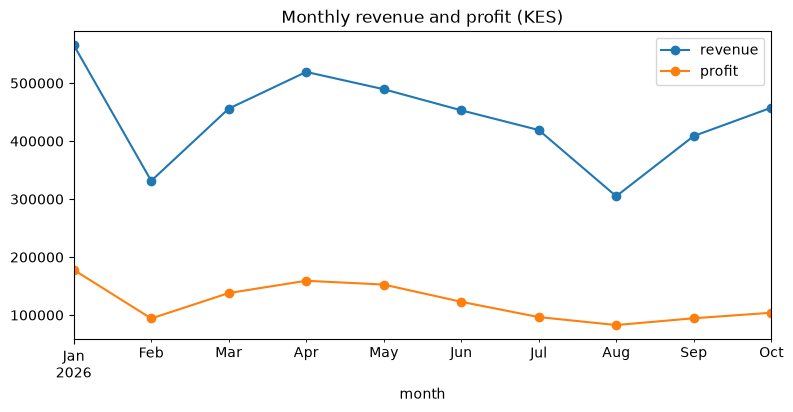

In [195]:
import matplotlib.pyplot as plt
monthly[["revenue", "profit"]].plot(marker="o", figsize=(9, 4))
plt.title("Monthly revenue and profit (KES)")
plt.show()

In [196]:
s = sales.dropna(subset=["order_date"]).copy()
s["period"] = s["order_date"].dt.month.ge(7).map({False: "Jan-Jun", True: "Jul-Oct"})

In [197]:
s.groupby(["category", "period"])[["revenue", "profit"]].sum()

revenue    profit
category    period                      
Apparel     Jan-Jun   508605.0  232005.0
            Jul-Oct   354945.0  164145.0
Electronics Jan-Jun  1399345.0  483195.0
            Jul-Oct   634260.0  127060.0
Groceries   Jan-Jun   656504.0   82569.0
            Jul-Oct   424566.0   52451.0
Household   Jan-Jun   250249.0   47029.0
            Jul-Oct   176426.5   34176.5

In [198]:
s.groupby(["category", "period"])["discount_pct"].mean().round(2)

category     period 
Apparel      Jan-Jun    0.01
             Jul-Oct    0.01
Electronics  Jan-Jun    0.01
             Jul-Oct    0.21
Groceries    Jan-Jun    0.01
             Jul-Oct    0.01
Household    Jan-Jun    0.01
             Jul-Oct    0.01
Name: discount_pct, dtype: float64

In [199]:
months = {"Jan-Jun": 6, "Jul-Oct": 4}
t = s.groupby(["category", "period"])[["revenue", "profit"]].sum()
t["months"]  = t.index.get_level_values("period").map(months)
t["rev_per_month"] = (t["revenue"] / t["months"]).round(0)
t["profit_per_month"] = (t["profit"] / t["months"]).round(0)
t[["rev_per_month", "profit_per_month"]]

rev_per_month  profit_per_month
category    period                                  
Apparel     Jan-Jun        84768.0           38668.0
            Jul-Oct        88736.0           41036.0
Electronics Jan-Jun       233224.0           80532.0
            Jul-Oct       158565.0           31765.0
Groceries   Jan-Jun       109417.0           13762.0
            Jul-Oct       106142.0           13113.0
Household   Jan-Jun        41708.0            7838.0
            Jul-Oct        44107.0            8544.0

so electronics alone explains the margin drop. Its revenue fell abot 32% per month and its profit about 61%, even though discounts rose from about 1% to about 21%. That discounting did not bring in extra sales.

In [200]:
t = s.groupby(["branch", "period"])[["revenue", "profit"]].sum()
t["months"] = t.index.get_level_values("period").map(months)
t["rev_per_month"] = (t["revenue"] / t["months"]).round(0)
t["profit_per_month"] = (t["profit"] / t["months"]). round(0)
t["margin_pct"] = (t["profit"] / t["revenue"] * 100).round(1)
t[["rev_per_month", "profit_per_month", "margin_pct"]]

rev_per_month  profit_per_month  margin_pct
branch  period                                              
Eldoret Jan-Jun        37273.0           11753.0        31.5
        Jul-Oct        41507.0           10390.0        25.0
Kisumu  Jan-Jun        62412.0           17666.0        28.3
        Jul-Oct        25376.0            5841.0        23.0
Mombasa Jan-Jun        83968.0           24570.0        29.3
        Jul-Oct        89995.0           21819.0        24.2
Nairobi Jan-Jun       189952.0           57353.0        30.2
        Jul-Oct       169581.0           42737.0        25.2
Nakuru  Jan-Jun        95511.0           29458.0        30.8
        Jul-Oct        71089.0           13671.0        19.2

Two findings:
1.  Every branch lost margin(5 to 12 points), which fits the electronics discounting being company-wide.
2. Kisumu has a separate problem. Its sales collapsed by about 59% while two branches grew, so discounts alone can not explain

Profit per month fell by about 46k in total. Nakuru lost the most(about 15.8k), then Nairobi(about 14.6k), then Kisumu (about 11.8k).
Kisumu has the worst sales drop, but Nakuru has the biggest profit loss. Both need a recommendation.

In [201]:
def per_month(df, by):
    t = df.groupby([by, "period"])[["revenue","profit"]].sum()
    t["months"] = t.index.get_level_values("period").map(months)
    return t[["revenue", "profit"]].div(t["months"], axis=0).round(0)

In [202]:
per_month(s[s["branch"] == "Kisumu"], "category")

revenue   profit
category    period                   
Apparel     Jan-Jun   8185.0   3835.0
            Jul-Oct   5925.0   2550.0
Electronics Jan-Jun  30120.0  10320.0
            Jul-Oct   6756.0   1419.0
Groceries   Jan-Jun  18512.0   2394.0
            Jul-Oct   9328.0   1192.0
Household   Jan-Jun   5596.0   1117.0
            Jul-Oct   3368.0    680.0

In [203]:
per_month(s[s["branch"] == "Nakuru"], "category")

revenue   profit
category    period                   
Apparel     Jan-Jun  16020.0   7670.0
            Jul-Oct  10140.0   4365.0
Electronics Jan-Jun  57367.0  18650.0
            Jul-Oct  33460.0   5272.0
Groceries   Jan-Jun  16464.0   2076.0
            Jul-Oct  18195.0   2261.0
Household   Jan-Jun   5660.0   1062.0
            Jul-Oct   9295.0   1772.0

What this shows:
1. Nakuru's problem is Electronics. Its profit fell about 15.8k a month, and about 13.4k of that (85%) is Electronics, where profit dropped from 18.7k to 5.3k. Groceries and household actually grew.
2. Kisumu's problem is everything. All four categories fell, and Groceries lost half its revenue even though it has no discount issue.When every category drops at oncee, the cause is likely something that hit the whole branch, such as fewer customers or stock, staff or opening problems.It is not a pricing issue.
3. Electronis still matters in Kisumu.It accounts for about 8.9k of Kisumu's 11.8k monthly profit(75%)

In [204]:
k = s[s["branch"] == "Kisumu"]
k.groupby("month")["order_id"].count()

month
2026-01    39
2026-02    40
2026-03    39
2026-04    43
2026-05    49
2026-06    42
2026-07    21
2026-08    22
2026-09    26
2026-10    14
Freq: M, Name: order_id, dtype: int64

In [205]:
per_month(k, "sales_rep")

revenue  profit
sales_rep period                  
Achieng   Jan-Jun  26301.0  8074.0
          Jul-Oct   9392.0  2576.0
Odhiambo  Jan-Jun  35340.0  9501.0
          Jul-Oct  14397.0  2813.0
Unknown   Jan-Jun    771.0    91.0
          Jul-Oct   1588.0   452.0

Kisumu orders per month: 
39 to 49 a month from January to June, then 21 in July, 22 in August, 26 in September and 14 in October. That’s a sudden drop in July that hasn’t recovered, not a slow slide.

Both reps fell by about the same amount:

1. Achieng: 26.3k → 9.4k per month 
2. Odhiambo: 35.3k → 14.4k per month
3. The small “Unknown” rep group is just the blank rep names you labelled earlier.

So it isn’t one person underperforming. Something hit the whole branch in July. Combined with the all-categories drop, that points to fewer customers or a shop-level issue (stock, opening hours, a nearby competitor, a staffing change). The data can’t tell which, so the recommendation is a visit and a conversation, not a data fix.

Three main findings:

1. Margin fell from about 30% to about 23% from July.
2. Electronics discounts (about 1% → 21%) drove it, with no sales boost.
3. Kisumu’s sales fell about 59% across every category and rep, starting in July.

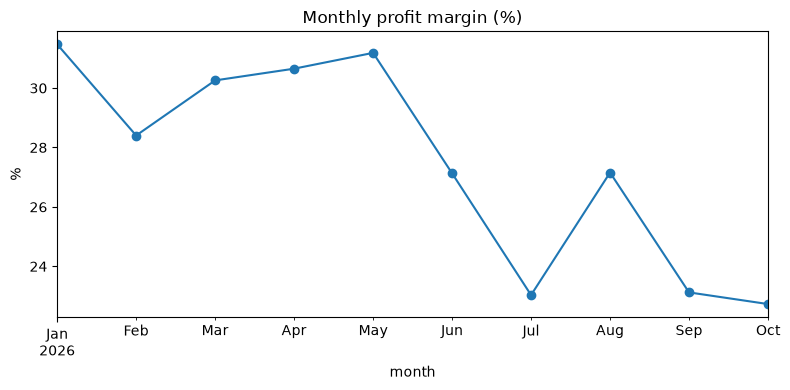

In [206]:
import matplotlib.pyplot as plt

m = sales.groupby("month")[["revenue", "profit"]].sum()
(m["profit"] / m["revenue"] * 100).plot(marker="o", figsize=(8, 4))
plt.title("Monthly profit margin (%)")
plt.ylabel("%")
plt.tight_layout()
plt.savefig("../reports/margin_trend.png")
plt.show()

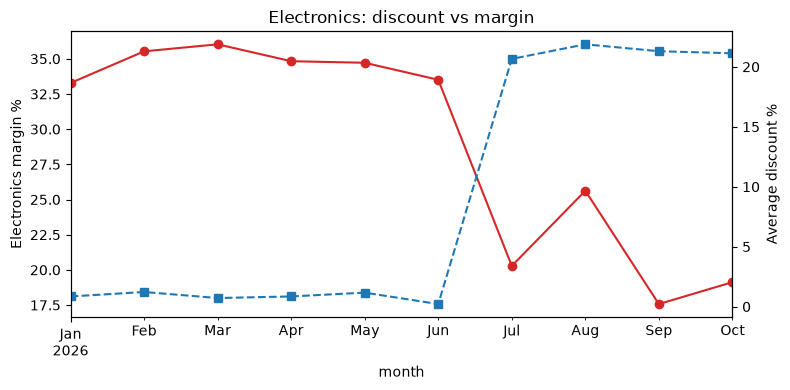

In [207]:
e = sales[sales["category"] == "Electronics"]
em = e.groupby("month").agg(revenue=("revenue", "sum"), profit=("profit", "sum"),
                            discount=("discount_pct", "mean"))
ax = (em["profit"] / em["revenue"] * 100).plot(marker="o", color="tab:red", figsize=(8, 4))
ax.set_ylabel("Electronics margin %")
ax2 = ax.twinx()
(em["discount"] * 100).plot(ax=ax2, marker="s", linestyle="--", color="tab:blue")
ax2.set_ylabel("Average discount %")
plt.title("Electronics: discount vs margin")
plt.tight_layout()
plt.savefig("../reports/electronics.png")
plt.show()

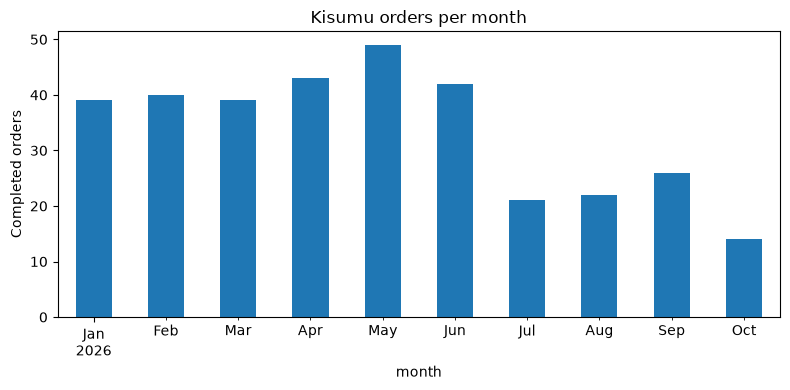

In [208]:
k.groupby("month")["order_id"].count().plot(kind="bar", figsize=(8, 4))
plt.title("Kisumu orders per month")
plt.ylabel  ("Completed orders")
plt.tight_layout()
plt.savefig("../reports/kisumu_orders.png")
plt.show()